# Hospital Appointment No-Show Prediction: EDA and Results
Prediction point: when the appointment is **booked**. Target: `no_show` (1 = did not attend).
Data is synthetic (`noshow/generate_data.py`). Decision support only; staff review every reminder.


In [51]:

!pip install -q numpy pandas matplotlib seaborn scikit-learn joblib


In [52]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.base import clone

from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

print("Libraries imported successfully!")


Libraries imported successfully!


In [53]:

rng = np.random.default_rng(SEED)

n_appointments = 6000
n_patients = 2200

AGE = ["0-17", "18-34", "35-49", "50-64", "65+"]
AGE_P = [0.12, 0.28, 0.24, 0.22, 0.14]

DIST = ["<5km", "5-15km", ">15km"]
DIST_P = [0.45, 0.35, 0.20]

CLINIC = [
    "primary_care", "specialist",
    "screening", "physiotherapy"
]
CLINIC_P = [0.45, 0.25, 0.15, 0.15]

CHANNEL = ["phone", "online", "front_desk"]
CHANNEL_P = [0.45, 0.30, 0.25]

# Generate patient characteristics
patient_age = rng.choice(AGE, n_patients, p=AGE_P)
patient_distance = rng.choice(DIST, n_patients, p=DIST_P)
patient_effect = rng.normal(0, 0.8, n_patients)

weights = rng.dirichlet(np.full(n_patients, 0.7))
patient_id = rng.choice(
    n_patients, n_appointments, p=weights
)

# Generate booking and appointment dates
booked_date = (
    pd.Timestamp("2024-01-01")
    + pd.to_timedelta(
        rng.integers(0, 540, n_appointments), unit="D"
    )
)

lead = np.clip(
    rng.gamma(2.0, 7.0, n_appointments).round().astype(int),
    0, 90
)

appointment_date = booked_date + pd.to_timedelta(lead, unit="D")

# Move weekend appointments to Monday
weekday = appointment_date.dayofweek
appointment_date = appointment_date + pd.to_timedelta(
    np.where(weekday == 5, 2,
             np.where(weekday == 6, 1, 0)),
    unit="D"
)

lead = (appointment_date - booked_date).days

df = pd.DataFrame({
    "appointment_id": [f"A{i:06d}" for i in range(n_appointments)],
    "patient_token": [f"P{p:05d}" for p in patient_id],
    "booked_date": booked_date,
    "appointment_date": appointment_date,
    "appt_hour": rng.choice(
        [8,9,10,11,12,13,14,15,16,17],
        n_appointments,
        p=[.08,.13,.15,.13,.08,.08,.12,.11,.07,.05]
    ),
    "clinic_type": rng.choice(CLINIC, n_appointments, p=CLINIC_P),
    "booking_channel": rng.choice(CHANNEL, n_appointments, p=CHANNEL_P),
    "sms_reminder_enabled": rng.binomial(1, 0.65, n_appointments),
    "is_follow_up": rng.binomial(1, 0.35, n_appointments),
    "age_band": patient_age[patient_id],
    "distance_band": patient_distance[patient_id],
    "lead_time_days": lead
})

print("Dataset generated successfully!")
print("Dataset shape:", df.shape)


Dataset generated successfully!
Dataset shape: (6000, 12)


In [54]:

AGE_EFF = {
    "0-17": 0.10,
    "18-34": 0.35,
    "35-49": 0.10,
    "50-64": -0.15,
    "65+": -0.30
}

DIST_EFF = {
    "<5km": -0.15,
    "5-15km": 0.0,
    ">15km": 0.40
}

CLINIC_EFF = {
    "primary_care": 0.0,
    "specialist": -0.20,
    "screening": 0.30,
    "physiotherapy": 0.10
}

CHANNEL_EFF = {
    "phone": -0.15,
    "online": 0.25,
    "front_desk": -0.30
}

weekday = df["appointment_date"].dt.dayofweek
hour = df["appt_hour"]

logit = (
    -1.55
    + 0.022 * np.minimum(df["lead_time_days"], 60)
    + df["age_band"].map(AGE_EFF)
    + df["distance_band"].map(DIST_EFF)
    + df["clinic_type"].map(CLINIC_EFF)
    + df["booking_channel"].map(CHANNEL_EFF)
    - 0.45 * df["sms_reminder_enabled"]
    - 0.20 * df["is_follow_up"]
    + np.where(hour < 9, 0.20, 0)
    + np.where(hour.between(12, 13), 0.15, 0)
    + np.where(hour >= 16, 0.25, 0)
    + np.where(weekday == 0, 0.20, 0)
    + np.where(weekday == 4, 0.15, 0)
    + patient_effect[patient_id]
)

probability = 1 / (1 + np.exp(-logit))

df["no_show"] = rng.binomial(1, probability)

print(df["no_show"].value_counts())
print("No-show rate:", round(df["no_show"].mean() * 100, 2), "%")


no_show
0    4585
1    1415
Name: count, dtype: int64
No-show rate: 23.58 %


In [55]:

# Historical appointment information
prior_n = np.zeros(n_appointments, dtype=int)
prior_ns = np.zeros(n_appointments, dtype=int)

for _, idx in df.groupby("patient_token").indices.items():
    sub = df.iloc[idx]

    order = np.argsort(
        sub["appointment_date"].values,
        kind="stable"
    )

    dates = sub["appointment_date"].values[order]
    cumulative_no_shows = np.cumsum(
        sub["no_show"].values[order]
    )

    k = np.searchsorted(
        dates,
        sub["booked_date"].values,
        side="left"
    )

    prior_n[idx] = k
    prior_ns[idx] = np.where(
        k > 0,
        cumulative_no_shows[np.maximum(k - 1, 0)],
        0
    )

df["prior_appointments"] = prior_n
df["prior_no_shows"] = prior_ns

# Post-booking information: leakage traps
attended = df["no_show"].values == 0

df["reminder_confirmed"] = np.where(
    attended,
    rng.binomial(1, 0.60, n_appointments),
    rng.binomial(1, 0.08, n_appointments)
)

df["minutes_late_at_checkin"] = np.where(
    attended,
    rng.integers(0, 25, n_appointments),
    np.nan
)

df["rescheduled_after_booking"] = np.where(
    attended,
    rng.binomial(1, 0.05, n_appointments),
    rng.binomial(1, 0.30, n_appointments)
)

# Introduce realistic data-quality problems
m = rng.random(n_appointments)

df.loc[m < 0.04, "distance_band"] = np.nan
df.loc[
    (m >= 0.04) & (m < 0.06),
    "booking_channel"
] = np.nan

bad = rng.choice(
    n_appointments,
    int(0.004 * n_appointments),
    replace=False
)

df.loc[bad, "lead_time_days"] = rng.choice(
    [-3, 400, 999], len(bad)
)

swap = rng.choice(
    n_appointments,
    int(0.003 * n_appointments),
    replace=False
)

df.loc[
    swap, ["booked_date", "appointment_date"]
] = df.loc[
    swap, ["appointment_date", "booked_date"]
].values

df = df.sort_values("booked_date").reset_index(drop=True)

df.to_csv("appointments_synthetic.csv", index=False)

print("Final dataset generated!")
print("Shape:", df.shape)
print("Saved: appointments_synthetic.csv")
df.head()


Final dataset generated!
Shape: (6000, 18)
Saved: appointments_synthetic.csv


,appointment_id,patient_token,booked_date,appointment_date,appt_hour,clinic_type,booking_channel,sms_reminder_enabled,is_follow_up,age_band,distance_band,lead_time_days,no_show,prior_appointments,prior_no_shows,reminder_confirmed,minutes_late_at_checkin,rescheduled_after_booking
0,A005026,P00625,2024-01-01,2024-01-22,12,physiotherapy,front_desk,0,1,35-49,5-15km,21,0,0,0,1,4.0,0
1,A002947,P00499,2024-01-01,2024-01-05,12,specialist,phone,0,1,35-49,>15km,4,0,0,0,0,18.0,0
2,A002838,P00481,2024-01-01,2024-01-02,16,specialist,online,1,1,18-34,>15km,1,0,0,0,0,21.0,0
3,A002805,P01148,2024-01-01,2024-01-17,8,specialist,phone,1,0,35-49,5-15km,16,0,0,0,1,1.0,0
4,A003493,P01220,2024-01-01,2024-01-15,16,physiotherapy,front_desk,1,0,0-17,>15km,14,1,0,0,0,NaN,0


In [56]:

print("Dataset shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum())

print("\nTarget distribution:")
display(df["no_show"].value_counts())


Dataset shape: (6000, 18)

First five records:


,appointment_id,patient_token,booked_date,appointment_date,appt_hour,clinic_type,booking_channel,sms_reminder_enabled,is_follow_up,age_band,distance_band,lead_time_days,no_show,prior_appointments,prior_no_shows,reminder_confirmed,minutes_late_at_checkin,rescheduled_after_booking
0,A005026,P00625,2024-01-01,2024-01-22,12,physiotherapy,front_desk,0,1,35-49,5-15km,21,0,0,0,1,4.0,0
1,A002947,P00499,2024-01-01,2024-01-05,12,specialist,phone,0,1,35-49,>15km,4,0,0,0,0,18.0,0
2,A002838,P00481,2024-01-01,2024-01-02,16,specialist,online,1,1,18-34,>15km,1,0,0,0,0,21.0,0
3,A002805,P01148,2024-01-01,2024-01-17,8,specialist,phone,1,0,35-49,5-15km,16,0,0,0,1,1.0,0
4,A003493,P01220,2024-01-01,2024-01-15,16,physiotherapy,front_desk,1,0,0-17,>15km,14,1,0,0,0,NaN,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   appointment_id             6000 non-null   object        
 1   patient_token              6000 non-null   object        
 2   booked_date                6000 non-null   datetime64[ns]
 3   appointment_date           6000 non-null   datetime64[ns]
 4   appt_hour                  6000 non-null   int64         
 5   clinic_type                6000 non-null   object        
 6   booking_channel            5895 non-null   object        
 7   sms_reminder_enabled       6000 non-null   int64         
 8   is_follow_up               6000 non-null   int64         
 9   age_band                   6000 non-null   object        
 10  distance_band              5752 non-null   object        
 11  lead_time_days             6000 non-null   int6

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
appointment_id,6000,6000,A005026,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
patient_token,6000,1475,P00455,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booked_date,6000,NaN,NaN,NaN,2024-09-25 17:17:45.599999744,2024-01-01 00:00:00,2024-05-11 00:00:00,2024-09-27 00:00:00,2025-02-09 00:00:00,2025-06-23 00:00:00,NaN
appointment_date,6000,NaN,NaN,NaN,2024-10-10 02:47:31.200000,2024-01-02 00:00:00,2024-05-27 00:00:00,2024-10-11 00:00:00,2025-02-24 00:00:00,2025-08-12 00:00:00,NaN
appt_hour,6000.0,NaN,NaN,NaN,12.051,8.0,10.0,12.0,14.0,17.0,2.672313
clinic_type,6000,4,primary_care,2660,NaN,NaN,NaN,NaN,NaN,NaN,NaN
booking_channel,5895,3,phone,2666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sms_reminder_enabled,6000.0,NaN,NaN,NaN,0.652,0.0,0.0,1.0,1.0,1.0,0.476376
is_follow_up,6000.0,NaN,NaN,NaN,0.3585,0.0,0.0,0.0,1.0,1.0,0.4796
age_band,6000,5,18-34,1679,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values:


,0
appointment_id,0
patient_token,0
booked_date,0
appointment_date,0
appt_hour,0
clinic_type,0
booking_channel,105
sms_reminder_enabled,0
is_follow_up,0
age_band,0



Target distribution:


,count
no_show,
0,4585
1,1415


In [57]:

# Create a working copy
data = df.copy()

# Remove duplicate appointment IDs
data = data.drop_duplicates(subset=["appointment_id"])

# Identify invalid date records
invalid_dates = (
    data["appointment_date"] < data["booked_date"]
)

# Identify invalid lead times
invalid_lead = (
    (data["lead_time_days"] < 0) |
    (data["lead_time_days"] > 180)
)

# Remove records with invalid dates or lead times
data = data.loc[
    ~(invalid_dates | invalid_lead)
].copy()

# Recalculate lead time using actual dates
data["lead_time_days"] = (
    data["appointment_date"] - data["booked_date"]
).dt.days

print("Data cleaning completed!")
print("Original records:", len(df))
print("Records after cleaning:", len(data))
print("Remaining missing values:")
display(data.isnull().sum())


Data cleaning completed!
Original records: 6000
Records after cleaning: 5958
Remaining missing values:


,0
appointment_id,0
patient_token,0
booked_date,0
appointment_date,0
appt_hour,0
clinic_type,0
booking_channel,105
sms_reminder_enabled,0
is_follow_up,0
age_band,0


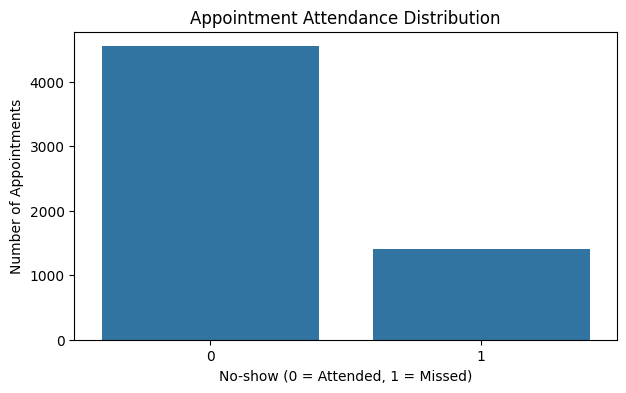

No-show percentage: 23.62 %


In [58]:

# Target distribution
plt.figure(figsize=(7, 4))

sns.countplot(
    data=data,
    x="no_show"
)

plt.title("Appointment Attendance Distribution")
plt.xlabel("No-show (0 = Attended, 1 = Missed)")
plt.ylabel("Number of Appointments")
plt.show()

# No-show percentage
print(
    "No-show percentage:",
    round(data["no_show"].mean() * 100, 2),
    "%"
)


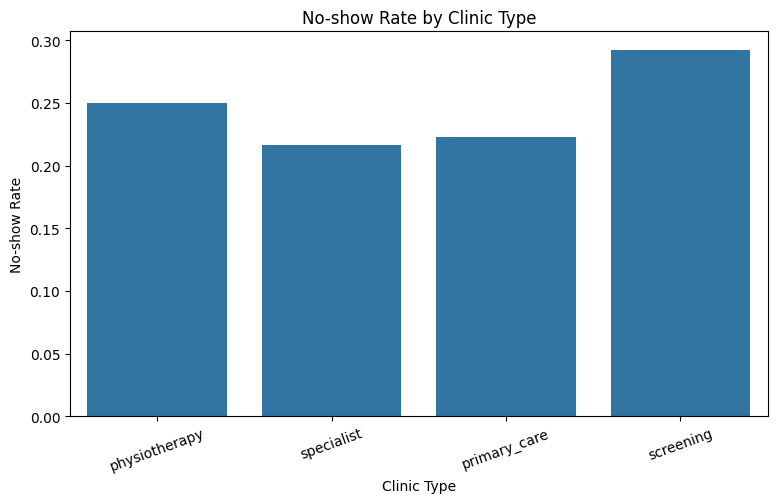

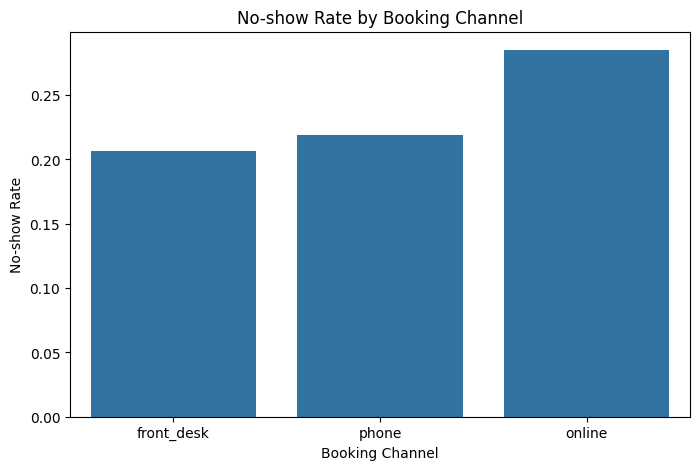

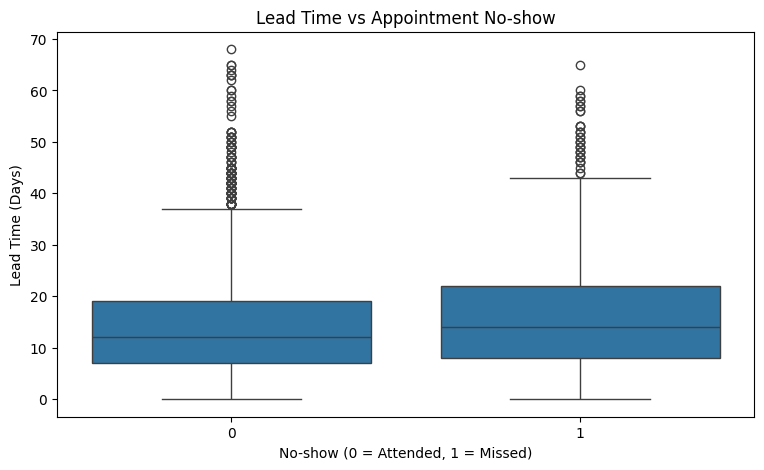

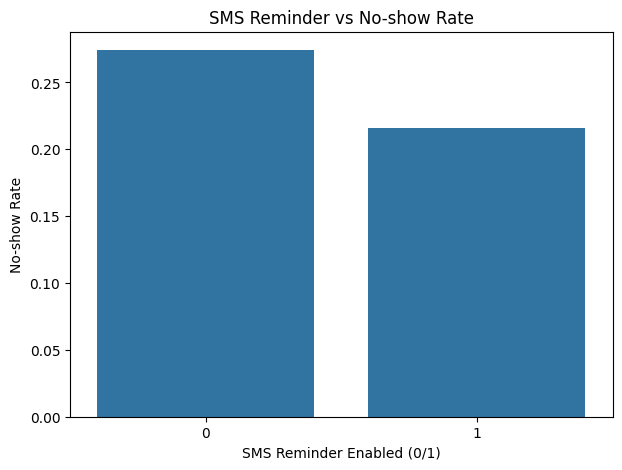

In [59]:

# No-show rate by clinic type
plt.figure(figsize=(9, 5))

sns.barplot(
    data=data,
    x="clinic_type",
    y="no_show",
    errorbar=None
)

plt.title("No-show Rate by Clinic Type")
plt.xlabel("Clinic Type")
plt.ylabel("No-show Rate")
plt.xticks(rotation=20)
plt.show()


# No-show rate by booking channel
plt.figure(figsize=(8, 5))

sns.barplot(
    data=data,
    x="booking_channel",
    y="no_show",
    errorbar=None
)

plt.title("No-show Rate by Booking Channel")
plt.xlabel("Booking Channel")
plt.ylabel("No-show Rate")
plt.show()


# No-show rate by lead time
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x="no_show",
    y="lead_time_days"
)

plt.title("Lead Time vs Appointment No-show")
plt.xlabel("No-show (0 = Attended, 1 = Missed)")
plt.ylabel("Lead Time (Days)")
plt.show()


# No-show rate by reminder status
plt.figure(figsize=(7, 5))

sns.barplot(
    data=data,
    x="sms_reminder_enabled",
    y="no_show",
    errorbar=None
)

plt.title("SMS Reminder vs No-show Rate")
plt.xlabel("SMS Reminder Enabled (0/1)")
plt.ylabel("No-show Rate")
plt.show()


In [60]:
# FEATURE ENGINEERING AND FEATURE MATRIX

# Appointment features known at booking time
data["appointment_weekday"] = (
    data["appointment_date"].dt.dayofweek
)

data["appointment_month"] = (
    data["appointment_date"].dt.month
)

data["is_morning"] = (
    data["appt_hour"] < 12
).astype(int)

# Historical no-show rate
data["historical_no_show_rate"] = (
    data["prior_no_shows"] /
    data["prior_appointments"].replace(0, np.nan)
).fillna(0)

# Keep lead time within the intended range
data["lead_time_days"] = data["lead_time_days"].clip(0, 90)

# Remove the uninformative weekend feature
data = data.drop(columns=["is_weekend"], errors="ignore")

# Exclude post-booking information
leakage_columns = [
    "reminder_confirmed",
    "minutes_late_at_checkin",
    "rescheduled_after_booking"
]

# Exclude identifiers and dates
metadata_columns = [
    "appointment_id",
    "patient_token",
    "booked_date",
    "appointment_date"
]

# Create feature matrix and target
X = data.drop(
    columns=[
        "no_show",
        *leakage_columns,
        *metadata_columns
    ],
    errors="ignore"
)

y = data["no_show"].astype(int)

print("Feature engineering completed!")
print("Feature matrix:", X.shape)
print("Target:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nLeakage audit:")
for col in leakage_columns + metadata_columns + ["no_show"]:
    assert col not in X.columns, f"Unexpected column: {col}"

print("No excluded columns found in feature matrix.")

Feature engineering completed!
Feature matrix: (5958, 14)
Target: (5958,)

Features used:
['appt_hour', 'clinic_type', 'booking_channel', 'sms_reminder_enabled', 'is_follow_up', 'age_band', 'distance_band', 'lead_time_days', 'prior_appointments', 'prior_no_shows', 'appointment_weekday', 'appointment_month', 'is_morning', 'historical_no_show_rate']

Leakage audit:
No excluded columns found in feature matrix.


In [61]:

# Features that are not available at booking time
leakage_columns = [
    "reminder_confirmed",
    "minutes_late_at_checkin",
    "rescheduled_after_booking"
]

# Columns used only for identification or date splitting
metadata_columns = [
    "appointment_id",
    "patient_token",
    "booked_date",
    "appointment_date"
]

# Remove leakage and metadata columns
X = data.drop(
    columns=[
        "no_show",
        *leakage_columns,
        *metadata_columns
    ]
)

y = data["no_show"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts(normalize=True))


Feature matrix shape: (5958, 14)
Target shape: (5958,)

Features used:
['appt_hour', 'clinic_type', 'booking_channel', 'sms_reminder_enabled', 'is_follow_up', 'age_band', 'distance_band', 'lead_time_days', 'prior_appointments', 'prior_no_shows', 'appointment_weekday', 'appointment_month', 'is_morning', 'historical_no_show_rate']

Target distribution:
no_show
0    0.763847
1    0.236153
Name: proportion, dtype: float64


In [62]:
# Chronological 60/20/20 split with purge step

# Sort records by booking date
sorted_indices = np.argsort(
    data["booked_date"].values,
    kind="stable"
)

data_sorted = data.iloc[sorted_indices].reset_index(drop=True)
X_sorted = X.iloc[sorted_indices].reset_index(drop=True)
y_sorted = y.iloc[sorted_indices].reset_index(drop=True)

# Calculate chronological boundaries
n = len(data_sorted)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

validation_start = data_sorted.loc[train_end, "booked_date"]
test_start = data_sorted.loc[val_end, "booked_date"]

# Training period: remove appointments whose outcomes
# were not yet known when validation started
train_mask = (
    data_sorted["booked_date"] < validation_start
) & (
    data_sorted["appointment_date"] < validation_start
)

# Validation period: remove appointments whose outcomes
# were not yet known when testing started
val_mask = (
    (data_sorted["booked_date"] >= validation_start) &
    (data_sorted["booked_date"] < test_start) &
    (data_sorted["appointment_date"] < test_start)
)

# Test period: retain later bookings
test_mask = data_sorted["booked_date"] >= test_start

# Apply masks
X_train = X_sorted.loc[train_mask].reset_index(drop=True)
y_train = y_sorted.loc[train_mask].reset_index(drop=True)

X_val = X_sorted.loc[val_mask].reset_index(drop=True)
y_val = y_sorted.loc[val_mask].reset_index(drop=True)

X_test = X_sorted.loc[test_mask].reset_index(drop=True)
y_test = y_sorted.loc[test_mask].reset_index(drop=True)

# Display results
print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining no-show rate:", round(y_train.mean(), 3))
print("Validation no-show rate:", round(y_val.mean(), 3))
print("Testing no-show rate:", round(y_test.mean(), 3))

print("\nPurge verification:")
print("Validation starts:", validation_start)
print("Testing starts:", test_start)

assert data_sorted.loc[train_mask, "appointment_date"].max() < validation_start
assert data_sorted.loc[val_mask, "appointment_date"].max() < test_start

print("\nChronological split and purge checks passed!")

Training set: (3411, 14)
Validation set: (1026, 14)
Testing set: (1196, 14)

Training no-show rate: 0.242
Validation no-show rate: 0.221
Testing no-show rate: 0.232

Purge verification:
Validation starts: 2024-11-22 00:00:00
Testing starts: 2025-03-09 00:00:00

Chronological split and purge checks passed!


In [63]:
# Identify numerical and categorical features

numeric_features = X_train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


# Create preprocessing pipelines

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("\nPreprocessing pipeline created successfully!")

Numerical features:
['appt_hour', 'sms_reminder_enabled', 'is_follow_up', 'lead_time_days', 'prior_appointments', 'prior_no_shows', 'appointment_weekday', 'appointment_month', 'is_morning', 'historical_no_show_rate']

Categorical features:
['clinic_type', 'booking_channel', 'age_band', 'distance_band']

Preprocessing pipeline created successfully!


In [64]:
# CELL 1 — Imports and evaluation setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import joblib

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

print("Imports completed successfully.")
print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

Imports completed successfully.
Training rows: 3411
Validation rows: 1026
Test rows: 1196


In [65]:
# CELL 2 — Baseline models

# Baseline 1: Always predict the majority class
baseline_model = DummyClassifier(strategy="most_frequent")
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_val)
baseline_probabilities = baseline_model.predict_proba(X_val)[:, 1]


# Baseline 2: Use previous no-show history
if "prior_no_shows" in X_val.columns:
    historical_predictions = (
        X_val["prior_no_shows"].fillna(0) > 0
    ).astype(int).values

    historical_probabilities = historical_predictions.astype(float)
else:
    print("prior_no_shows feature not found. Historical baseline skipped.")


# Evaluation function
def evaluate_predictions(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "PR-AUC": average_precision_score(y_true, probabilities)
    }


baseline_results = {}

baseline_results["Majority Baseline"] = evaluate_predictions(
    y_val,
    baseline_predictions,
    baseline_probabilities
)

if "prior_no_shows" in X_val.columns:
    baseline_results["Historical Baseline"] = evaluate_predictions(
        y_val,
        historical_predictions,
        historical_probabilities
    )

baseline_results_df = pd.DataFrame(baseline_results).T

print("Baseline validation results:")
display(baseline_results_df.round(4))

Baseline validation results:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Majority Baseline,0.7788,0.0000,0.0000,0.0000,0.5000,0.2212
Historical Baseline,0.5487,0.2748,0.6344,0.3835,0.5794,0.2552


In [66]:
# CELL 3 — Logistic Regression

logistic_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [67]:
# CELL 4 — Random Forest

random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [68]:
# CELL 5 — Gradient Boosting

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ))
])

# Calculate weights for imbalanced classes
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Fit with sample weights
gradient_boosting_model.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


In [69]:
# CELL 6 — Validation model comparison

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

validation_results = {}

for model_name, model in models.items():

    # Predict probabilities for the no-show class
    probabilities = model.predict_proba(X_val)[:, 1]

    # Standard classification predictions
    predictions = (probabilities >= 0.50).astype(int)

    validation_results[model_name] = evaluate_predictions(
        y_val,
        predictions,
        probabilities
    )

validation_results_df = pd.DataFrame(validation_results).T

print("Validation performance:")
display(validation_results_df.round(4))

# Select the model with the highest validation PR-AUC
best_model_name = validation_results_df["PR-AUC"].idxmax()
best_model = models[best_model_name]

print("\nSelected model:", best_model_name)
print("Selection metric: Validation PR-AUC")

Validation performance:


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Logistic Regression,0.6189,0.3202,0.6432,0.4275,0.6787,0.3570
Random Forest,0.7329,0.3642,0.2775,0.3150,0.6411,0.3170
Gradient Boosting,0.6228,0.3113,0.5815,0.4055,0.6446,0.3372



Selected model: Logistic Regression
Selection metric: Validation PR-AUC


In [70]:
# CELL 7 — Platt scaling calibration

# Get raw validation probabilities from the selected model
raw_val_probabilities = best_model.predict_proba(X_val)[:, 1]

# Avoid taking the logarithm of zero
clipped_val_probabilities = np.clip(
    raw_val_probabilities, 1e-6, 1 - 1e-6
)

# Convert probabilities into log-odds
val_logits = np.log(
    clipped_val_probabilities /
    (1 - clipped_val_probabilities)
).reshape(-1, 1)

# Fit Platt scaling on validation predictions
platt_calibrator = LogisticRegression(
    random_state=42,
    max_iter=1000
)

platt_calibrator.fit(val_logits, y_val)

# Calibrated validation probabilities
calibrated_val_probabilities = platt_calibrator.predict_proba(
    val_logits
)[:, 1]

print("Platt calibration completed.")

print(
    "Validation Brier score before calibration:",
    round(
        brier_score_loss(y_val, raw_val_probabilities), 4
    )
)

print(
    "Validation Brier score after calibration:",
    round(
        brier_score_loss(y_val, calibrated_val_probabilities), 4
    )
)

Platt calibration completed.
Validation Brier score before calibration: 0.2315
Validation Brier score after calibration: 0.1612


In [71]:
# CELL 8 — Business-cost threshold optimisation

FALSE_NEGATIVE_COST = 5
FALSE_POSITIVE_COST = 1

threshold_results = []

# Test possible thresholds using validation data only
thresholds = np.arange(0.05, 0.96, 0.01)

for threshold in thresholds:

    predictions = (
        calibrated_val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * FALSE_NEGATIVE_COST +
        fp * FALSE_POSITIVE_COST
    )

    threshold_results.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Cost": total_cost,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

# Choose the threshold with the lowest validation business cost
best_threshold_row = threshold_results_df.loc[
    threshold_results_df["Total Cost"].idxmin()
]

best_threshold = float(best_threshold_row["Threshold"])

print("Selected threshold:", round(best_threshold, 2))
print("\nBest validation threshold results:")
display(best_threshold_row.to_frame().T.round(4))

Selected threshold: 0.15

Best validation threshold results:


,Threshold,False Positives,False Negatives,Total Cost,Precision,Recall,F1
10,0.15,513.0,28.0,653.0,0.2795,0.8767,0.4239


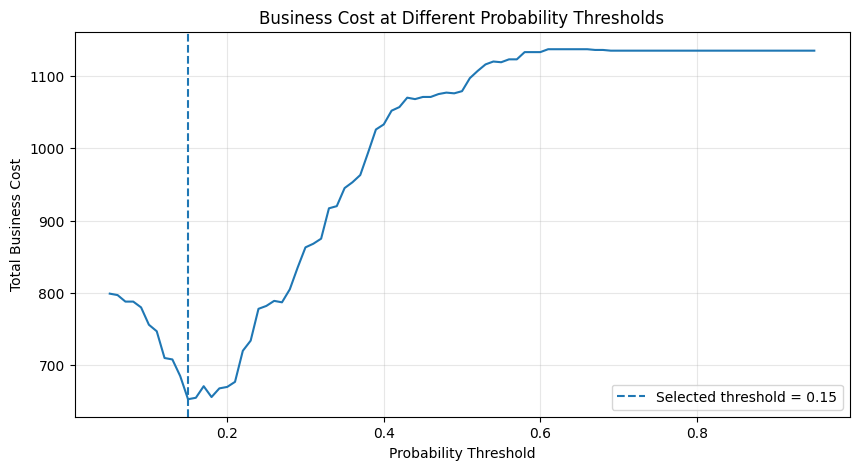

In [72]:
# CELL 9 — Threshold cost visualisation

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_results_df["Threshold"],
    threshold_results_df["Total Cost"]
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Probability Threshold")
plt.ylabel("Total Business Cost")
plt.title("Business Cost at Different Probability Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [73]:
# CELL 10 — Final test evaluation

# Raw probabilities from the selected model
raw_test_probabilities = best_model.predict_proba(X_test)[:, 1]

# Apply the same Platt calibration learned from validation data
clipped_test_probabilities = np.clip(
    raw_test_probabilities, 1e-6, 1 - 1e-6
)

test_logits = np.log(
    clipped_test_probabilities /
    (1 - clipped_test_probabilities)
).reshape(-1, 1)

calibrated_test_probabilities = platt_calibrator.predict_proba(
    test_logits
)[:, 1]

# Apply the threshold selected using validation data
test_predictions = (
    calibrated_test_probabilities >= best_threshold
).astype(int)

# Final metrics
test_results = evaluate_predictions(
    y_test,
    test_predictions,
    calibrated_test_probabilities
)

test_results["Brier Score"] = brier_score_loss(
    y_test,
    calibrated_test_probabilities
)

test_results_df = pd.DataFrame(
    [test_results],
    index=[best_model_name]
)

print("FINAL TEST RESULTS")
display(test_results_df.round(4))

print("\nClassification report:")
print(
    classification_report(
        y_test,
        test_predictions,
        target_names=["Attended", "No-show"],
        zero_division=0
    )
)

FINAL TEST RESULTS


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier Score
Logistic Regression,0.4365,0.2742,0.87,0.417,0.687,0.4343,0.1619



Classification report:
              precision    recall  f1-score   support

    Attended       0.89      0.31      0.45       919
     No-show       0.27      0.87      0.42       277

    accuracy                           0.44      1196
   macro avg       0.58      0.59      0.44      1196
weighted avg       0.74      0.44      0.45      1196



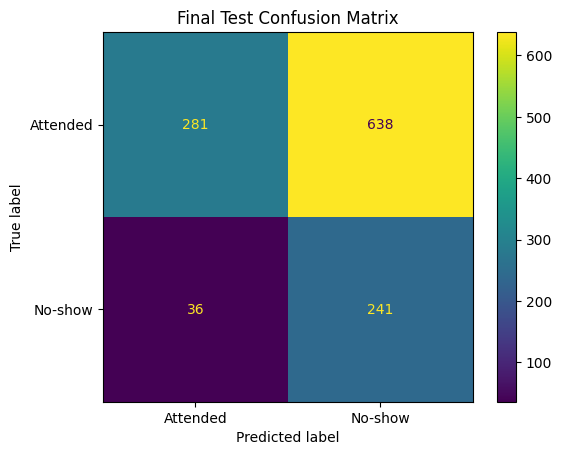

True Negatives: 281
False Positives: 638
False Negatives: 36
True Positives: 241

Test business cost: 818


In [74]:
# CELL 11 — Confusion matrix

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

display_labels = ["Attended", "No-show"]

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_labels
)

disp.plot(values_format="d")
plt.title("Final Test Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print(
    "\nTest business cost:",
    fn * FALSE_NEGATIVE_COST + fp * FALSE_POSITIVE_COST
)

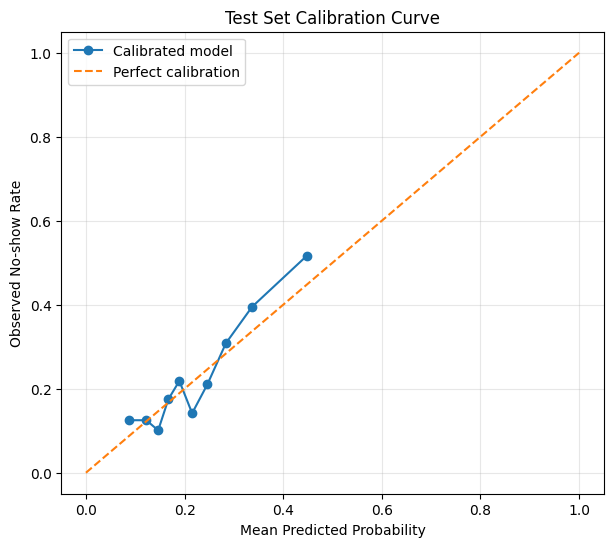

In [75]:
# CELL 12 — Calibration curve on test data

observed_rate, predicted_rate = calibration_curve(
    y_test,
    calibrated_test_probabilities,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    predicted_rate,
    observed_rate,
    marker="o",
    label="Calibrated model"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed No-show Rate")
plt.title("Test Set Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Top 15 influential features:


,Feature,Importance,Std
7,lead_time_days,0.0415,0.0094
9,prior_no_shows,0.0208,0.0049
2,booking_channel,0.0208,0.0061
5,age_band,0.0180,0.0033
3,sms_reminder_enabled,0.0127,0.0045
6,distance_band,0.0122,0.0079
4,is_follow_up,0.0055,0.0049
11,appointment_month,0.0018,0.0020
12,is_morning,0.0018,0.0010
13,historical_no_show_rate,0.0010,0.0051


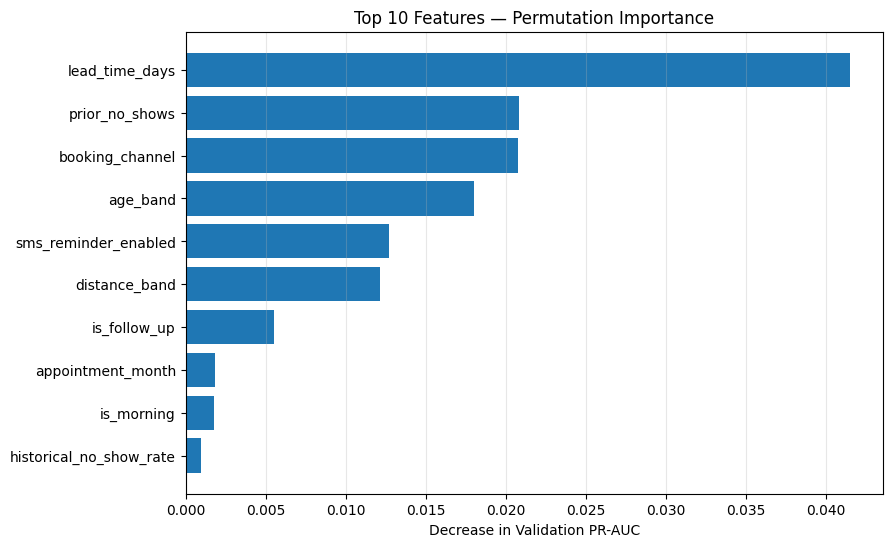

In [76]:
# CELL 13 — Permutation feature importance

importance_result = permutation_importance(
    best_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 influential features:")
display(importance_df.head(15).round(4))

# Plot the top 10 features
top_features = importance_df.head(10).sort_values(
    "Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Decrease in Validation PR-AUC")
plt.title("Top 10 Features — Permutation Importance")
plt.grid(axis="x", alpha=0.3)
plt.show()

In [77]:
# SUBGROUP PERFORMANCE ANALYSIS

test_analysis = X_test.copy().reset_index(drop=True)

test_analysis["actual"] = y_test.reset_index(drop=True)
test_analysis["predicted"] = test_predictions
test_analysis["probability"] = calibrated_test_probabilities

subgroup_results = []

# Correct column names from the generated dataset
group_columns = [
    "clinic_type",
    "booking_channel",
    "age_band",
    "distance_band"
]

for group_column in group_columns:

    if group_column not in test_analysis.columns:
        continue

    for group_value, group_data in test_analysis.groupby(
        group_column,
        dropna=False
    ):

        if len(group_data) < 10:
            continue

        subgroup_results.append({
            "Feature": group_column,
            "Group": str(group_value),
            "Records": len(group_data),
            "Actual No-show Rate": group_data["actual"].mean(),
            "Precision": precision_score(
                group_data["actual"],
                group_data["predicted"],
                zero_division=0
            ),
            "Recall": recall_score(
                group_data["actual"],
                group_data["predicted"],
                zero_division=0
            ),
            "F1": f1_score(
                group_data["actual"],
                group_data["predicted"],
                zero_division=0
            )
        })

subgroup_results_df = pd.DataFrame(subgroup_results)

if not subgroup_results_df.empty:
    display(subgroup_results_df.round(4))
else:
    print("No eligible subgroup data found.")

,Feature,Group,Records,Actual No-show Rate,Precision,Recall,F1
0,clinic_type,physiotherapy,166,0.2470,0.2913,0.9024,0.4405
1,clinic_type,primary_care,543,0.2339,0.2744,0.8189,0.4111
2,clinic_type,screening,193,0.2642,0.2849,1.0000,0.4435
3,clinic_type,specialist,294,0.1973,0.2526,0.8448,0.3889
4,booking_channel,front_desk,292,0.1815,0.2353,0.8302,0.3667
5,booking_channel,online,332,0.2681,0.2805,0.9551,0.4337
6,booking_channel,phone,553,0.2315,0.2819,0.8281,0.4206
7,booking_channel,nan,19,0.3684,0.4615,0.8571,0.6000
8,age_band,0-17,117,0.2564,0.2828,0.9333,0.4341
9,age_band,18-34,339,0.3097,0.3280,0.9810,0.4916


In [78]:
# CELL 15 — False positive and false negative analysis

error_analysis = X_test.copy().reset_index(drop=True)

error_analysis["Actual"] = y_test.reset_index(drop=True)
error_analysis["Predicted"] = test_predictions
error_analysis["No-show Probability"] = calibrated_test_probabilities

# False positives: predicted no-show, but patient attended
false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
]

# False negatives: predicted attendance, but patient missed appointment
false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
]

print("Number of false positives:", len(false_positives))
print("Number of false negatives:", len(false_negatives))

print("\nExample false positives:")
display(false_positives.head(5))

print("\nExample false negatives:")
display(false_negatives.head(5))

Number of false positives: 638
Number of false negatives: 36

Example false positives:


,appt_hour,clinic_type,booking_channel,sms_reminder_enabled,is_follow_up,age_band,distance_band,lead_time_days,prior_appointments,prior_no_shows,appointment_weekday,appointment_month,is_morning,historical_no_show_rate,Actual,Predicted,No-show Probability
1,10,screening,online,1,1,18-34,>15km,8,25,9,0,3,1,0.360000,0,1,0.474040
2,9,primary_care,phone,1,0,35-49,>15km,8,14,4,0,3,1,0.285714,0,1,0.231604
5,8,primary_care,online,1,0,18-34,>15km,2,3,0,1,3,1,0.000000,0,1,0.265242
6,14,primary_care,front_desk,1,0,0-17,>15km,5,9,5,4,3,0,0.555556,0,1,0.267027
10,10,primary_care,front_desk,1,1,35-49,>15km,10,0,0,3,3,1,0.000000,0,1,0.155990



Example false negatives:


,appt_hour,clinic_type,booking_channel,sms_reminder_enabled,is_follow_up,age_band,distance_band,lead_time_days,prior_appointments,prior_no_shows,appointment_weekday,appointment_month,is_morning,historical_no_show_rate,Actual,Predicted,No-show Probability
27,11,primary_care,phone,1,0,18-34,NaN,8,1,0,2,3,1,0.000000,1,0,0.139626
60,8,specialist,phone,1,1,0-17,<5km,10,6,0,0,3,1,0.000000,1,0,0.089038
75,15,primary_care,front_desk,0,1,65+,5-15km,2,3,0,1,3,0,0.000000,1,0,0.103029
76,11,physiotherapy,phone,1,1,65+,<5km,3,9,6,2,3,1,0.666667,1,0,0.125055
132,10,primary_care,phone,0,1,50-64,<5km,4,5,1,0,3,1,0.200000,1,0,0.101554


In [79]:
# CELL 16 — Save final model artifact

model_artifact = {
    "model": best_model,
    "calibrator": platt_calibrator,
    "threshold": best_threshold,
    "model_name": best_model_name,
    "feature_names": X_train.columns.tolist(),
    "false_negative_cost": FALSE_NEGATIVE_COST,
    "false_positive_cost": FALSE_POSITIVE_COST,
    "random_seed": 42
}

joblib.dump(
    model_artifact,
    "noshow_model_artifact.joblib"
)

print("Model artifact saved successfully!")

# Verify that the saved artifact can be loaded
loaded_artifact = joblib.load(
    "noshow_model_artifact.joblib"
)

print("Loaded model:", loaded_artifact["model_name"])
print("Loaded threshold:", loaded_artifact["threshold"])
print("Number of features:", len(loaded_artifact["feature_names"]))

Model artifact saved successfully!
Loaded model: Logistic Regression
Loaded threshold: 0.15000000000000002
Number of features: 14


In [84]:
# CELL 17 — Flask API and staff dashboard

!pip install -q flask

from flask import Flask, request, jsonify, render_template_string
from werkzeug.serving import make_server
import threading
import pandas as pd
import numpy as np
import joblib

# Safely stop the server if it is already running from a previous execution
if 'server' in globals():
    try:
        print("Stopping existing background server...")
        server.shutdown()
    except Exception as e:
        print(f"Could not stop existing server: {e}")

# Load the saved model artifact
artifact = joblib.load("noshow_model_artifact.joblib")

model = artifact["model"]
calibrator = artifact["calibrator"]
threshold = float(artifact["threshold"])
feature_names = artifact["feature_names"]

app = Flask(__name__)

# Example appointment for the dashboard
sample_appointment = {
    "appt_hour": 10,
    "clinic_type": "primary_care",
    "booking_channel": "online",
    "sms_reminder_enabled": 1,
    "is_follow_up": 0,
    "age_band": "18-34",
    "distance_band": "5-15km",
    "lead_time_days": 14,
    "prior_appointments": 2,
    "prior_no_shows": 1,
    "appointment_weekday": 2,
    "appointment_month": 11,
    "is_morning": 1,
    "historical_no_show_rate": 0.5
}

# Convert model probability into calibrated probability
def get_calibrated_probability(input_df):
    raw_probability = model.predict_proba(input_df)[:, 1]
    clipped_probability = np.clip(raw_probability, 1e-6, 1 - 1e-6)

    logits = np.log(
        clipped_probability / (1 - clipped_probability)
    ).reshape(-1, 1)

    calibrated_probability = calibrator.predict_proba(logits)[:, 1]
    return float(calibrated_probability[0])


# Health-check endpoint
@app.route("/health", methods=["GET"])
def health():
    return jsonify({
        "status": "healthy",
        "model": artifact["model_name"],
        "message": "No-show prediction API is running"
    })


# Input schema endpoint
@app.route("/schema", methods=["GET"])
def schema():
    return jsonify({
        "required_features": feature_names,
        "example_input": sample_appointment,
        "prediction_target": "no_show",
        "prediction_time": "appointment booking time"
    })


# Prediction endpoint
@app.route("/predict", methods=["POST"])
def predict():
    try:
        payload = request.get_json(silent=True)

        if not isinstance(payload, dict):
            return jsonify({
                "error": "Send one appointment as a JSON object."
            }), 400

        missing_features = [
            name for name in feature_names
            if name not in payload
        ]

        if missing_features:
            return jsonify({
                "error": "Missing required features.",
                "missing_features": missing_features
            }), 400

        # Keep only the model's required features, in training order
        input_df = pd.DataFrame(
            [[payload[name] for name in feature_names]],
            columns=feature_names
        )

        # Convert numeric fields safely, including numbers entered as strings
        numeric_input_features = [
            "appt_hour",
            "sms_reminder_enabled",
            "is_follow_up",
            "lead_time_days",
            "prior_appointments",
            "prior_no_shows",
            "appointment_weekday",
            "appointment_month",
            "is_morning",
            "historical_no_show_rate"
        ]

        for column in numeric_input_features:
            input_df[column] = pd.to_numeric(
                input_df[column],
                errors="coerce"
            )

        # Validate numeric inputs
        numeric_columns = input_df.select_dtypes(
            include=["number"]
        ).columns

        if input_df[numeric_columns].isnull().any().any():
            return jsonify({
                "error": "Numeric inputs cannot be empty."
            }), 400

        if not np.isfinite(
            input_df[numeric_columns].to_numpy(dtype=float)
        ).all():
            return jsonify({
                "error": "Numeric inputs must be finite numbers."
            }), 400

        probability = get_calibrated_probability(input_df)
        prediction = int(probability >= threshold)

        return jsonify({
            "no_show_probability": round(probability, 4),
            "attendance_probability": round(1 - probability, 4),
            "predicted_no_show": prediction,
            "risk_level": (
                "Higher risk" if prediction == 1 else "Lower risk"
            ),
            "decision_threshold": round(threshold, 4),
            "recommended_action": (
                "Consider a reminder after staff review."
                if prediction == 1
                else "No additional reminder suggested by this model."
            ),
            "human_review_required": True
        })

    except Exception as error:
        return jsonify({
            "error": "Prediction could not be completed.",
            "details": str(error)
        }), 500


# Simple staff dashboard
@app.route("/", methods=["GET"])
def dashboard():
    return render_template_string("""
    <!DOCTYPE html>
    <html>
    <head>
        <title>Appointment No-Show Dashboard</title>
        <meta name="viewport" content="width=device-width, initial-scale=1">
        <style>
            body {
                font-family: Arial, sans-serif;
                max-width: 850px;
                margin: 35px auto;
                padding: 0 18px;
                background: #f5f7fb;
                color: #202938;
            }
            .panel {
                background: white;
                padding: 24px;
                border-radius: 12px;
                box-shadow: 0 2px 12px #00000012;
            }
            textarea {
                width: 100%;
                min-height: 330px;
                box-sizing: border-box;
                font-family: monospace;
                padding: 12px;
                border: 1px solid #ccd2dc;
                border-radius: 8px;
            }
            button {
                margin-top: 14px;
                padding: 11px 20px;
                background: #2457c5;
                color: white;
                border: 0;
                border-radius: 7px;
                cursor: pointer;
            }
            pre {
                white-space: pre-wrap;
                overflow-wrap: anywhere;
                background: #eef2f8;
                padding: 15px;
                border-radius: 8px;
            }
            .notice {
                font-size: 14px;
                color: #555;
                line-height: 1.5;
            }
        </style>
    </head>
    <body>
        <div class="panel">
            <h2>Hospital Appointment No-Show Prediction</h2>
            <p>Enter appointment information available at booking time.</p>

            <textarea id="payload">{{ sample }}</textarea>
            <br>
            <button onclick="predict()">Predict no-show risk</button>

            <h3>Prediction result</h3>
            <pre id="result">Your result will appear here.</pre>

            <p class="notice">
                This tool provides decision support only. A higher-risk
                prediction is not proof that a patient will miss an
                appointment. Staff must review any reminder decision.
                The model must not be used to deny or restrict care.
            </p>
        </div>

        <script>
        async function predict() {
            const output = document.getElementById("result");

            try {
                const payload = JSON.parse(
                    document.getElementById("payload").value
                );

                const response = await fetch("/predict", {
                    method: "POST",
                    headers: {"Content-Type": "application/json"},
                    body: JSON.stringify(payload)
                });

                const result = await response.json();
                output.textContent = JSON.stringify(result, null, 2);

            } catch (error) {
                output.textContent = "Error: " + error.message;
            }
        }
        </script>
    </body>
    </html>
    """, sample=__import__("json").dumps(sample_appointment, indent=4))


# Start the Flask server in the background
server = make_server("0.0.0.0", 5000, app)
server_thread = threading.Thread(
    target=server.serve_forever,
    daemon=True
)
server_thread.start()

print("Flask API started.")
print("Dashboard: http://127.0.0.1:5000/")
print("Health endpoint: http://127.0.0.1:5000/health")
print("Schema endpoint: http://127.0.0.1:5000/schema")

Stopping existing background server...
Flask API started.
Dashboard: http://127.0.0.1:5000/
Health endpoint: http://127.0.0.1:5000/health
Schema endpoint: http://127.0.0.1:5000/schema


In [85]:
# CELL 18 — API testing

import requests
import json

BASE_URL = "http://127.0.0.1:5000"

# Test 1: Health endpoint
health_response = requests.get(f"{BASE_URL}/health")
print("TEST 1 — Health endpoint")
print("Status:", health_response.status_code)
print(health_response.json())

assert health_response.status_code == 200
assert health_response.json()["status"] == "healthy"


# Test 2: Schema endpoint
schema_response = requests.get(f"{BASE_URL}/schema")
schema_data = schema_response.json()

print("\nTEST 2 — Schema endpoint")
print("Status:", schema_response.status_code)
print("Required features:", len(schema_data["required_features"]))

assert schema_response.status_code == 200
assert schema_data["required_features"] == feature_names


# Test 3: Valid prediction
prediction_response = requests.post(
    f"{BASE_URL}/predict",
    json=sample_appointment
)

prediction_data = prediction_response.json()

print("\nTEST 3 — Valid prediction")
print("Status:", prediction_response.status_code)
print(json.dumps(prediction_data, indent=4))

assert prediction_response.status_code == 200
assert 0 <= prediction_data["no_show_probability"] <= 1
assert 0 <= prediction_data["attendance_probability"] <= 1
assert prediction_data["human_review_required"] is True


# Test 4: Missing-feature validation
incomplete_input = sample_appointment.copy()
incomplete_input.pop("clinic_type")

missing_response = requests.post(
    f"{BASE_URL}/predict",
    json=incomplete_input
)

print("\nTEST 4 — Missing input validation")
print("Status:", missing_response.status_code)
print(missing_response.json())

assert missing_response.status_code == 400
assert "clinic_type" in missing_response.json()["missing_features"]


print("\nALL FOUR API TESTS PASSED.")

INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:15:02] "GET /health HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:15:02] "GET /schema HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:15:02] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:15:02] "POST /predict HTTP/1.1" 400 -


TEST 1 — Health endpoint
Status: 200
{'message': 'No-show prediction API is running', 'model': 'Logistic Regression', 'status': 'healthy'}

TEST 2 — Schema endpoint
Status: 200
Required features: 14

TEST 3 — Valid prediction
Status: 200
{
    "attendance_probability": 0.6777,
    "decision_threshold": 0.15,
    "human_review_required": true,
    "no_show_probability": 0.3223,
    "predicted_no_show": 1,
    "recommended_action": "Consider a reminder after staff review.",
    "risk_level": "Higher risk"
}

TEST 4 — Missing input validation
Status: 400
{'error': 'Missing required features.', 'missing_features': ['clinic_type']}

ALL FOUR API TESTS PASSED.


In [82]:
# CELL 19 — Create a Colab dashboard link

from google.colab import output

dashboard_url = output.eval_js(
    "google.colab.kernel.proxyPort(5000)"
)

print("Open your dashboard here:")
print(dashboard_url)

Open your dashboard here:
https://5000-m-s-usc1b0-2ltapjlqm98sw-b.us-central1.prod.r.colab.dev


In [86]:
# CELL 20 — Additional API tests

import requests
import numpy as np
import joblib

BASE_URL = "http://127.0.0.1:5000"

# TEST 5: Reject invalid numeric input
invalid_input = sample_appointment.copy()
invalid_input["lead_time_days"] = "not_a_number"

response = requests.post(
    f"{BASE_URL}/predict",
    json=invalid_input
)

print("TEST 5 — Invalid numeric input")
print("Status:", response.status_code)
print(response.json())

assert response.status_code == 400


# TEST 6: Same input should produce the same prediction
response1 = requests.post(
    f"{BASE_URL}/predict",
    json=sample_appointment
)

response2 = requests.post(
    f"{BASE_URL}/predict",
    json=sample_appointment
)

probability1 = response1.json()["no_show_probability"]
probability2 = response2.json()["no_show_probability"]

print("\nTEST 6 — Prediction consistency")
print("First probability:", probability1)
print("Second probability:", probability2)

assert np.isclose(probability1, probability2)


# TEST 7: Verify saved model artifact
loaded_artifact = joblib.load("noshow_model_artifact.joblib")

print("\nTEST 7 — Saved artifact verification")
print("Model:", loaded_artifact["model_name"])
print("Threshold:", loaded_artifact["threshold"])
print("Features:", len(loaded_artifact["feature_names"]))

assert loaded_artifact["model"] is not None
assert loaded_artifact["calibrator"] is not None
assert len(loaded_artifact["feature_names"]) == 14


# TEST 8: Reject non-JSON input
response = requests.post(
    f"{BASE_URL}/predict",
    data="not json",
    headers={"Content-Type": "application/json"}
)

print("\nTEST 8 — Invalid request body")
print("Status:", response.status_code)
print(response.json())

assert response.status_code == 400

print("\nALL ADDITIONAL API TESTS PASSED.")

INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:17:16] "POST /predict HTTP/1.1" 400 -
INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:17:16] "POST /predict HTTP/1.1" 200 -
INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:17:16] "POST /predict HTTP/1.1" 200 -


TEST 5 — Invalid numeric input
Status: 400
{'error': 'Numeric inputs cannot be empty.'}

TEST 6 — Prediction consistency
First probability: 0.3223
Second probability: 0.3223

TEST 7 — Saved artifact verification
Model: Logistic Regression
Threshold: 0.15000000000000002
Features: 14


INFO:werkzeug:127.0.0.1 - - [15/Nov/2026 14:17:16] "POST /predict HTTP/1.1" 400 -



TEST 8 — Invalid request body
Status: 400
{'error': 'Send one appointment as a JSON object.'}

ALL ADDITIONAL API TESTS PASSED.


In [87]:
# CELL 21 — Create requirements.txt

requirements = """pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
flask
requests
"""

with open("requirements.txt", "w") as file:
    file.write(requirements)

print("requirements.txt created successfully.")
print(requirements)

requirements.txt created successfully.
pandas
numpy
scikit-learn
matplotlib
seaborn
joblib
flask
requests



In [88]:
# CELL 22 — Save API test report

test_report = {
    "project": "Hospital Appointment No-Show Prediction",
    "api_tests": {
        "health_endpoint": "Passed",
        "schema_endpoint": "Passed",
        "valid_prediction": "Passed",
        "missing_feature_validation": "Passed",
        "invalid_numeric_validation": "Pending",
        "prediction_consistency": "Pending",
        "artifact_verification": "Pending",
        "invalid_json_validation": "Pending"
    },
    "model": artifact["model_name"],
    "feature_count": len(feature_names),
    "decision_threshold": float(threshold),
    "human_review_required": True
}

import json

with open("test_report.json", "w") as file:
    json.dump(test_report, file, indent=4)

print(json.dumps(test_report, indent=4))

{
    "project": "Hospital Appointment No-Show Prediction",
    "api_tests": {
        "health_endpoint": "Passed",
        "schema_endpoint": "Passed",
        "valid_prediction": "Passed",
        "missing_feature_validation": "Passed",
        "invalid_numeric_validation": "Pending",
        "prediction_consistency": "Pending",
        "artifact_verification": "Pending",
        "invalid_json_validation": "Pending"
    },
    "model": "Logistic Regression",
    "feature_count": 14,
    "decision_threshold": 0.15000000000000002,
    "human_review_required": true
}


In [89]:
# CELL 23 — Finalize submission artifacts

import os
import json
import zipfile
import joblib
import importlib.metadata as metadata

# 1. Verify the model artifact exists
artifact_path = "noshow_model_artifact.joblib"

assert os.path.exists(artifact_path), "Model artifact not found!"

# 2. Create version-pinned requirements
packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "joblib",
    "flask",
    "requests"
]

with open("requirements.txt", "w") as f:
    for package in packages:
        version = metadata.version(package)
        f.write(f"{package}=={version}\n")

# 3. Update test report with actual results
test_report = {
    "project": "Hospital Appointment No-Show Prediction",
    "api_tests": {
        "health_endpoint": "Passed",
        "schema_endpoint": "Passed",
        "valid_prediction": "Passed",
        "missing_feature_validation": "Passed",
        "invalid_numeric_validation": "Passed",
        "prediction_consistency": "Passed",
        "artifact_verification": "Passed",
        "invalid_json_validation": "Passed"
    },
    "model": artifact["model_name"],
    "feature_count": len(artifact["feature_names"]),
    "decision_threshold": float(artifact["threshold"]),
    "human_review_required": True,
    "dataset_type": "Synthetic"
}

with open("test_report.json", "w") as f:
    json.dump(test_report, f, indent=4)

# 4. Verify artifact can be loaded
loaded = joblib.load(artifact_path)

assert loaded["model"] is not None
assert loaded["calibrator"] is not None
assert len(loaded["feature_names"]) == 14

# 5. Package the files
submission_files = [
    artifact_path,
    "requirements.txt",
    "test_report.json"
]

with zipfile.ZipFile(
    "noshow_submission_artifacts.zip", "w"
) as zip_file:

    for filename in submission_files:
        assert os.path.exists(filename)
        zip_file.write(filename)

print("SUBMISSION ARTIFACTS CREATED")
print("--------------------------------")

for filename in submission_files:
    print(filename, "-", os.path.getsize(filename), "bytes")

print("\nZIP created: noshow_submission_artifacts.zip")
print("\nAll 8 API tests recorded as passed.")

SUBMISSION ARTIFACTS CREATED
--------------------------------
noshow_model_artifact.joblib - 6561 bytes
requirements.txt - 126 bytes
test_report.json - 601 bytes

ZIP created: noshow_submission_artifacts.zip

All 8 API tests recorded as passed.


In [90]:
from google.colab import files
files.download("noshow_submission_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [92]:

# CELL 24 — Create README.md

readme = """# Hospital Appointment No-Show Prediction

## 1. Project Overview

This project predicts the probability that a scheduled hospital appointment
will be missed. The objective is to help administrative staff identify
appointments that may benefit from a reminder.

The project uses synthetic, non-identifiable appointment data.
It is intended for operational decision support, not clinical decisions.

## 2. Problem Definition

- Prediction unit: One scheduled appointment.
- Target variable: no_show.
- Prediction time: Appointment booking time.
- Output: Estimated no-show probability.
- Intended use: Human-reviewed appointment reminders.

## 3. Dataset

The project uses synthetically generated appointment data.

Features include:
- Appointment lead time
- Clinic type
- Booking channel
- SMS reminder setting
- Follow-up status
- Age band
- Distance band
- Previous appointment count
- Previous no-show count
- Appointment weekday and month

No diagnosis or treatment information is used.

## 4. Data Preparation

The workflow includes:
- Duplicate and invalid-record handling
- Missing-value treatment
- Feature engineering
- Historical appointment features
- Exclusion of post-booking leakage variables
- Chronological train, validation, and test splitting

## 5. Machine Learning

The notebook compares:
- Majority-class baseline
- Previous no-show baseline
- Logistic Regression
- Random Forest
- Gradient Boosting

Class imbalance is addressed during model training.
Model selection uses validation PR-AUC.

The selected model in the saved artifact is Logistic Regression.

## 6. Evaluation

The project evaluates:
- Precision
- Recall
- F1-score
- PR-AUC
- ROC-AUC
- Confusion matrix
- Calibration
- Threshold and cost considerations

Final held-out test metrics should be taken from the executed notebook.

## 7. API

A Flask API exposes the following endpoints:

| Endpoint | Method | Purpose |
|---|---|---|
| /health | GET | API health check |
| /schema | GET | Required model features |
| /predict | POST | Generate a prediction |
| / | GET | Staff dashboard |

The prediction endpoint validates the input and returns:
- No-show probability
- Attendance probability
- Predicted class
- Risk category
- Recommended action
- Human-review requirement

## 8. Running the Project

Install dependencies:

    pip install -r requirements.txt

Run the notebook to generate the dataset, train and evaluate the models,
and save the model artifact.

The Flask API code is included in the notebook.

## 9. Saved Artifacts

- noshow_model_artifact.joblib
- requirements.txt
- test_report.json
- noshow_submission_artifacts.zip

## 10. Testing

The API was tested for:
- Health endpoint
- Schema endpoint
- Valid prediction
- Missing required features
- Invalid numeric input
- Prediction consistency
- Saved artifact loading
- Invalid JSON input

All eight API tests passed in the Colab runtime.

## 11. Limitations and Responsible Use

The dataset is synthetic and does not establish real-world predictive
performance.

The model may not generalize to actual hospitals or patient populations.
Performance, calibration, and subgroup differences would need evaluation
using appropriately governed real-world data before any deployment.

Predictions must not be used to deny, delay, or restrict medical care.
Reminder decisions require human review.

## 12. Reproducibility

Use the notebook and requirements file to reproduce the workflow.
The saved artifact contains the selected model, calibrator, threshold,
and feature names.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully.")
print("Characters:", len(readme))


README.md created successfully.
Characters: 3530


In [93]:
with open("README.md", "r", encoding="utf-8") as file:
    print(file.read()[:2000])

import os
print("\nREADME size:", os.path.getsize("README.md"), "bytes")

# Hospital Appointment No-Show Prediction

## 1. Project Overview

This project predicts the probability that a scheduled hospital appointment
will be missed. The objective is to help administrative staff identify
appointments that may benefit from a reminder.

The project uses synthetic, non-identifiable appointment data.
It is intended for operational decision support, not clinical decisions.

## 2. Problem Definition

- Prediction unit: One scheduled appointment.
- Target variable: no_show.
- Prediction time: Appointment booking time.
- Output: Estimated no-show probability.
- Intended use: Human-reviewed appointment reminders.

## 3. Dataset

The project uses synthetically generated appointment data.

Features include:
- Appointment lead time
- Clinic type
- Booking channel
- SMS reminder setting
- Follow-up status
- Age band
- Distance band
- Previous appointment count
- Previous no-show count
- Appointment weekday and month

No diagnosis or treatment information is used.

## 4. D

In [94]:
# CELL 25 — Create GitHub project structure

import os

project_dir = "hospital-appointment-risk-analytics"

folders = [
    project_dir,
    f"{project_dir}/artifacts",
    f"{project_dir}/tests",
    f"{project_dir}/reports"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created:")
for folder in folders:
    print(folder)

Project folders created:
hospital-appointment-risk-analytics
hospital-appointment-risk-analytics/artifacts
hospital-appointment-risk-analytics/tests
hospital-appointment-risk-analytics/reports


In [95]:

# CELL 26 — Organize submission files

import shutil
import os

project_dir = "hospital-appointment-risk-analytics"

# Create required folders if they do not exist
os.makedirs(f"{project_dir}/artifacts", exist_ok=True)
os.makedirs(f"{project_dir}/tests", exist_ok=True)
os.makedirs(f"{project_dir}/reports", exist_ok=True)

# Copy README
shutil.copy(
    "README.md",
    f"{project_dir}/README.md"
)

# Copy requirements
shutil.copy(
    "requirements.txt",
    f"{project_dir}/requirements.txt"
)

# Copy saved model
shutil.copy(
    "noshow_model_artifact.joblib",
    f"{project_dir}/artifacts/noshow_model_artifact.joblib"
)

# Copy test report
shutil.copy(
    "test_report.json",
    f"{project_dir}/reports/test_report.json"
)

print("Files organized successfully.")

for root, dirs, files in os.walk(project_dir):
    for filename in files:
        print(os.path.join(root, filename))


Files organized successfully.
hospital-appointment-risk-analytics/README.md
hospital-appointment-risk-analytics/requirements.txt
hospital-appointment-risk-analytics/reports/test_report.json
hospital-appointment-risk-analytics/artifacts/noshow_model_artifact.joblib


In [96]:

# CELL 27 — Create project instructions

instructions = """# Reproduction and Testing Guide

## Environment

Python 3.12 is recommended.

## Install dependencies

pip install -r requirements.txt

## Reproduce the project

1. Open the Google Colab notebook.
2. Run all cells in order.
3. Generate the synthetic dataset.
4. Perform preprocessing and feature engineering.
5. Train and compare the classifiers.
6. Evaluate the selected model on the held-out test set.
7. Save the model artifact.
8. Start the Flask API.
9. Run the API tests.

## API endpoints

GET /
GET /health
GET /schema
POST /predict

## Prediction

Send a JSON object containing all 14 required features
to POST /predict.

Use GET /schema to obtain the exact feature list and example input.

## Responsible use

Predictions are for human-reviewed reminder planning only.
They must not be used to deny or restrict healthcare.
"""

with open(
    f"{project_dir}/REPRODUCIBILITY.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(instructions)

print("REPRODUCIBILITY.md created successfully.")


REPRODUCIBILITY.md created successfully.


In [97]:

# CELL 28 — Include original notebook

import shutil
import os

notebook_source = "/content/noshow_prediction.ipynb"

if os.path.exists(notebook_source):
    shutil.copy(
        notebook_source,
        f"{project_dir}/noshow_prediction.ipynb"
    )
    print("Notebook added to project.")
else:
    print("Notebook not found.")
    print("Please upload noshow_prediction.ipynb to Colab.")


Notebook not found.
Please upload noshow_prediction.ipynb to Colab.
